<a href="https://colab.research.google.com/github/asthaa717/analisis-multivariat/blob/main/analisis_multivariiat_8.2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load Dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA

# ===== 1. Load data =====
data = load_wine(as_frame=True)
df = data.frame.drop(columns="target")

sumber data: https://archive.ics.uci.edu/dataset/109/wine

Aeberhard, S. & Forina, M. (1992). Wine [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J.

# Membagi data menjadi dua

In [3]:
X_cols = ["alcohol", "malic_acid", "ash",
          "alcalinity_of_ash", "magnesium"]
Y_cols = ["total_phenols", "flavanoids",
          "proanthocyanins", "color_intensity", "hue"]

X = df[X_cols]
Y = df[Y_cols]

n_comp = min(X.shape[1], Y.shape[1])
comp_names = [f"CV{i+1}" for i in range(n_comp)]

# Korelasi Silang X dan Y

In [4]:
combined = pd.concat([X, Y], axis=1)
corr = combined.corr()

cross_corr = corr.loc[X.columns, Y.columns]
print(cross_corr.round(3))

                   total_phenols  flavanoids  proanthocyanins  \
alcohol                    0.289       0.237            0.137   
malic_acid                -0.335      -0.411           -0.221   
ash                        0.129       0.115            0.010   
alcalinity_of_ash         -0.321      -0.351           -0.197   
magnesium                  0.214       0.196            0.236   

                   color_intensity    hue  
alcohol                      0.546 -0.072  
malic_acid                   0.249 -0.561  
ash                          0.259 -0.075  
alcalinity_of_ash            0.019 -0.274  
magnesium                    0.200  0.055  


Hasil korelasi silang menunjukkan bahwa hubungan antara variabel set X dan set Y secara umum lemah sampai sedang. Hubungan terkuat adalah korelasi negatif antara malic_acid dan hue (-0,561) serta korelasi positif antara alcohol dan color_intensity (0,546), yang berarti anggur dengan kadar asam malat lebih tinggi cenderung memiliki hue lebih rendah, sedangkan anggur beralkohol lebih tinggi cenderung berwarna lebih pekat. Malic_acid juga berkorelasi negatif dengan flavanoids (-0,411) dan total_phenols (-0,335), begitu pula alcalinity_of_ash dengan flavanoids (-0,351) dan total_phenols (-0,321). Sebaliknya, ash dan magnesium hampir tidak memiliki hubungan berarti dengan variabel di set Y (nilai korelasi di bawah 0,26), dan sebagian besar pasangan lainnya bernilai di bawah 0,3, sehingga hubungan lintas set bersifat moderat dan lebih tepat dianalisis secara gabungan melalui CCA.

# Standarisasi

In [5]:
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_x.fit_transform(X)
Y_scaled = scaler_y.fit_transform(Y)

# CCA

In [6]:
cca = CCA(n_components=n_comp,
          scale=False,
          max_iter=1000)

U, V = cca.fit_transform(X_scaled,
                         Y_scaled)

print(U.shape)
print(V.shape)

(178, 5)
(178, 5)


In [7]:
canonical_correlations = []
for i in range(n_comp):
    r = np.corrcoef(U[:, i],
                    V[:, i])[0, 1]
    canonical_correlations.append(r)

for i, r in enumerate(
        canonical_correlations, start=1):
    print(f"Canonical Correlation "
          f"{i}: {r:.3f}")

Canonical Correlation 1: 0.729
Canonical Correlation 2: 0.583
Canonical Correlation 3: 0.238
Canonical Correlation 4: 0.146
Canonical Correlation 5: 0.013


Hasil korelasi kanonik menunjukkan bahwa fungsi kanonik pertama memiliki korelasi sebesar 0,729 (menjelaskan sekitar 53,1% varians bersama), yang tergolong kuat, dan fungsi kedua sebesar 0,583 (sekitar 34,0%), yang tergolong cukup kuat. Sebaliknya, fungsi ketiga sampai kelima hanya bernilai 0,238, 0,146, dan 0,013, sehingga hubungannya lemah dan hampir tidak bermakna. Hal ini menunjukkan bahwa keterkaitan antara set variabel X (sifat kimia dasar) dan set variabel Y (senyawa fenolik dan warna) terutama terwakili oleh dua fungsi kanonik pertama, sehingga hanya dua fungsi tersebut yang layak diinterpretasikan lebih lanjut.

# Bobot Kanonik

## Weights

In [8]:
# weights
x_weights = pd.DataFrame(
    cca.x_weights_,
    index=X.columns,
    columns=comp_names)
print(x_weights.round(3))

y_weights = pd.DataFrame(
    cca.y_weights_,
    index=Y.columns,
    columns=comp_names)
print(y_weights.round(3))

                     CV1    CV2    CV3    CV4    CV5
alcohol            0.663  0.686  0.149 -0.132 -0.223
malic_acid        -0.489  0.637 -0.432  0.410 -0.026
ash                0.458 -0.074 -0.534  0.142  0.693
alcalinity_of_ash -0.330  0.340  0.295 -0.573  0.600
magnesium          0.049  0.051  0.647  0.683  0.332
                   CV1    CV2    CV3    CV4    CV5
total_phenols    0.133  0.136  0.064  0.274 -0.940
flavanoids       0.518 -0.234 -0.535  0.600  0.177
proanthocyanins -0.212  0.004  0.648  0.698  0.218
color_intensity  0.708  0.589  0.324 -0.141  0.166
hue              0.410 -0.762  0.430 -0.241 -0.093


Bobot kanonik menunjukkan kontribusi relatif tiap variabel dalam membentuk variat kanonik. Pada fungsi pertama (CV1), set X didominasi oleh alcohol (0,663), dengan kontribusi positif dari ash (0,458) dan negatif dari malic_acid (-0,489) serta alcalinity_of_ash (-0,330), sedangkan set Y didominasi oleh color_intensity (0,708), flavanoids (0,518), dan hue (0,410), sementara total_phenols (0,133) dan proanthocyanins (-0,212) berkontribusi kecil. Pada fungsi kedua (CV2), set X dibentuk terutama oleh alcohol (0,686) dan malic_acid (0,637), sedangkan set Y oleh hue yang berbobot negatif besar (-0,762) dan color_intensity yang berbobot positif (0,589), yang menggambarkan hubungan antara alkohol dan asam malat tinggi dengan warna pekat bernuansa hue rendah. Fungsi ketiga sampai kelima didominasi oleh variabel yang berbeda-beda, seperti magnesium dan proanthocyanins pada CV3 dan CV4 serta ash dan total_phenols pada CV5, tetapi karena korelasi kanoniknya lemah, bobot-bobot ini tidak perlu diinterpretasikan secara mendalam. Perlu diingat bahwa bobot dapat dipengaruhi multikolinearitas antarvariabel, misalnya proanthocyanins yang berbobot negatif pada CV1 padahal loading-nya positif, sehingga interpretasi utama sebaiknya mengacu pada loading kanonik.

## Loadings

In [9]:
x_loadings = pd.DataFrame(
    {f"CV{i+1}": [
        np.corrcoef(X_scaled[:, j],
                    U[:, i])[0, 1]
        for j in range(X_scaled.shape[1])]
     for i in range(n_comp)},
    index=X.columns)
print(x_loadings.round(3))

y_loadings = pd.DataFrame(
    {f"CV{i+1}": [
        np.corrcoef(Y_scaled[:, j],
                    V[:, i])[0, 1]
        for j in range(Y_scaled.shape[1])]
     for i in range(n_comp)},
    index=Y.columns)
print(y_loadings.round(3))

                     CV1    CV2    CV3    CV4    CV5
alcohol            0.782  0.555  0.073 -0.090 -0.258
malic_acid        -0.424  0.829 -0.190  0.310 -0.030
ash                0.363  0.302 -0.357  0.078  0.802
alcalinity_of_ash -0.451  0.322  0.031 -0.459  0.694
magnesium          0.390  0.111  0.661  0.502  0.384
                   CV1    CV2    CV3    CV4    CV5
total_phenols    0.687 -0.302  0.016  0.519 -0.409
flavanoids       0.694 -0.465 -0.073  0.539  0.077
proanthocyanins  0.362 -0.224  0.647  0.625  0.095
color_intensity  0.469  0.847  0.157 -0.182  0.072
hue              0.370 -0.891  0.151 -0.211 -0.041


Hasil loading kanonik menunjukkan bahwa pada fungsi kanonik pertama (CV1), set X dicirikan oleh alcohol yang berloading positif tertinggi (0,782) serta malic_acid (-0,424) dan alcalinity_of_ash (-0,451) yang berloading negatif, sedangkan seluruh variabel set Y berloading positif, terutama flavanoids (0,694) dan total_phenols (0,687). Artinya, anggur dengan kadar alkohol lebih tinggi serta asam malat dan alkalinitas abu lebih rendah cenderung memiliki kandungan flavonoid dan fenol yang lebih tinggi. Pada fungsi kedua (CV2), set X didominasi oleh malic_acid (0,829) dan alcohol (0,555), sedangkan pada set Y color_intensity berloading positif tinggi (0,847) dan hue berloading negatif tinggi (-0,891), yang berarti anggur dengan asam malat dan alkohol tinggi cenderung berwarna lebih pekat dengan hue lebih rendah. Fungsi ketiga sampai kelima memiliki loading yang tinggi pada beberapa variabel, seperti magnesium dan proanthocyanins pada CV3, tetapi karena korelasi kanoniknya lemah, fungsi-fungsi tersebut tidak perlu diinterpretasikan secara mendalam.

# Visualisasi

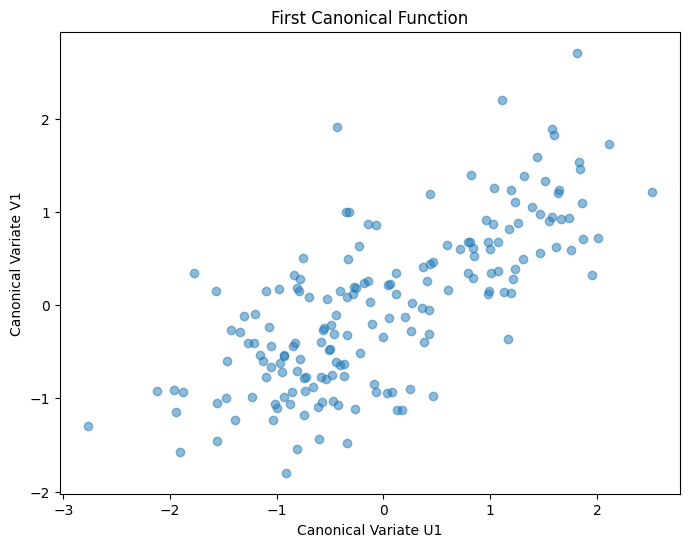

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(U[:, 0], V[:, 0], alpha=0.5)
plt.xlabel("Canonical Variate U1")
plt.ylabel("Canonical Variate V1")
plt.title("First Canonical Function")
plt.show()

Scatter plot antara variat kanonik U1 dan V1 menunjukkan pola hubungan linear positif, di mana semakin tinggi skor U1 (kombinasi variabel kimia dasar) maka semakin tinggi pula skor V1 (kombinasi variabel fenolik dan warna). Pola ini sesuai dengan korelasi kanonik pertama sebesar 0,729, yang tergolong kuat. Titik-titik tampak menyebar di sekitar garis tren imajiner tanpa pola melengkung, sehingga asumsi linearitas relatif terpenuhi. Sebaran yang masih cukup lebar menandakan hubungan tersebut kuat tetapi tidak sempurna. Terdapat beberapa titik yang agak menjauh dari kelompok utama, seperti titik dengan U1 sekitar -2,8 dan V1 sekitar -1,3 serta titik dengan V1 sekitar 2,7, yang dapat dicurigai sebagai outlier, tetapi jumlahnya sedikit dan tampaknya tidak memengaruhi pola hubungan secara keseluruhan.

In [11]:
from sklearn.cross_decomposition import CCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_x.fit_transform(X)
Y_scaled = scaler_y.fit_transform(Y)

cca = CCA(n_components=3, scale=False,
          max_iter=1000)
U, V = cca.fit_transform(X_scaled, Y_scaled)

In [12]:
r = np.array([
    np.corrcoef(U[:, i], V[:, i])[0, 1]
    for i in range(3)
])

print(np.round(r, 3))
print(np.round(r**2, 3))

[0.729 0.583 0.238]
[0.531 0.34  0.057]


In [13]:
x_loadings = np.column_stack([
    [np.corrcoef(X_scaled[:, j],
                 U[:, i])[0, 1]
     for j in range(X_scaled.shape[1])]
    for i in range(3)
])

y_loadings = np.column_stack([
    [np.corrcoef(Y_scaled[:, j],
                 V[:, i])[0, 1]
     for j in range(Y_scaled.shape[1])]
    for i in range(3)
])

In [14]:
x_cross = np.column_stack([
    [np.corrcoef(X_scaled[:, j],
                 V[:, i])[0, 1]
     for j in range(X_scaled.shape[1])]
    for i in range(3)
])

y_cross = np.column_stack([
    [np.corrcoef(Y_scaled[:, j],
                 U[:, i])[0, 1]
     for j in range(Y_scaled.shape[1])]
    for i in range(3)
])

In [16]:
ve_x = np.mean(x_loadings**2, axis=0)
ve_y = np.mean(y_loadings**2, axis=0)

print("VE X:", np.round(ve_x, 3))
print("VE Y:", np.round(ve_y, 3))

VE X: [0.256 0.24  0.121]
VE Y: [0.288 0.374 0.094]


In [17]:
red_x = ve_x * (r**2)
red_y = ve_y * (r**2)

print("Redundancy X from Y:", np.round(red_x, 3))
print("Redundancy Y from X:", np.round(red_y, 3))

Redundancy X from Y: [0.136 0.082 0.007]
Redundancy Y from X: [0.153 0.127 0.005]


In [18]:
from scipy.stats import chi2

n = X_scaled.shape[0]
p = X_scaled.shape[1]
q = Y_scaled.shape[1]
results = []

for k in range(len(r)):
    wilks = np.prod(1 - r[k:]**2)
    corr = n - 1 - (p + q + 1) / 2
    chi = -corr * np.log(wilks)
    df = (p - k) * (q - k)
    p_val = chi2.sf(chi, df)
    results.append([k + 1, wilks, chi, df, p_val])

test_table = pd.DataFrame(results, columns=[
    "Start_Function", "Wilks_Lambda",
    "Chi_Square", "df", "p_value"
])

print(test_table.round(4))

   Start_Function  Wilks_Lambda  Chi_Square  df  p_value
0               1        0.2919    211.1958  25   0.0000
1               2        0.6227     81.2338  16   0.0000
2               3        0.9435      9.9744   9   0.3526
